# Uygulama 5 – Yapay Sinir Ağlarının Geliştirilmesi ve Kullanılması: Kümeleme (SOM)
**Sena Köse** · YMH451 Yapay Zeka

Veri setleri:
- `airline-safety.csv` – 56 havayolu, 1985–1999 ve 2000–2014 kaza/ölümcül kaza/ölüm sayıları (uygulamanın kendisi)
- `Mall_Customers.csv` – 200 AVM müşterisi; yaş, yıllık gelir, harcama puanı (Soru 1)
- `CC_GENERAL.csv` – 8950 kredi kartı sahibi, 17 kullanım davranışı özelliği (Soru 2)

## SOM nasıl çalışır?
**Öz-düzenleyici harita (Self-Organizing Map, Kohonen ağı)** denetimsiz öğrenen bir yapay sinir ağıdır: veride etiket yoktur, ağ benzer örnekleri kendiliğinden yan yana koymayı öğrenir.

1. Ağ, 2 boyutlu bir ızgaraya dizilmiş nöronlardan oluşur (burada 20×20 = 400 nöron). Her nöronun girdiyle **aynı boyutta** bir ağırlık vektörü vardır (havayolu verisinde 6 sayı).
2. Ağırlıklar başlangıçta verinin min–max aralığında rastgele seçilir.
3. Her epokta veriden rastgele bir örnek alınır ve ağırlığı bu örneğe Öklid uzaklığı en yakın nöron bulunur: **BMU** (Best Matching Unit, kazanan nöron).
4. BMU ve ızgarada ona yakın komşuları örneğe doğru çekilir: `w ← w + η(t) · h(t) · (x − w)`. Burada `η` öğrenme katsayısı, `h` komşuluk fonksiyonudur (BMU'ya uzak nöronlar daha az güncellenir).
5. Eğitim ilerledikçe hem `η` hem komşuluk yarıçapı küçülür: önce harita kabaca şekillenir, sonra ince ayar yapılır.

Sonuçta **girdi uzayında benzer olan örnekler haritada da yakın nöronlara düşer.** 6 boyutlu veri 2 boyuta indirilmiş olur. Uygulamada her örneğin BMU koordinatı (`net.project`) alınıp bu 2 boyutlu noktalar **K-Means** ile 3 kümeye ayrılıyor; yani SOM boyut indirgeme ve topoloji koruma işini, K-Means ise son sınırları çizme işini yapıyor.

**Periyodik sınır koşulu (PBC):** Izgaranın sağ kenarı sol kenarına, üst kenarı alt kenarına bağlıdır (simit/torus şekli). Kenardaki nöronların daha az komşusu olması sorunu ortadan kalkar.

> **Basitçe:** SOM, etiketsiz veriyi 2 boyutlu bir haritaya yerleştiren bir sinir ağı. Haritadaki her nöron veriyle aynı boyutta bir "örnek vektör" taşıyor. Eğitimde rastgele bir örnek alınıyor, ona en çok benzeyen nöron (kazanan) ve komşuları o örneğe doğru biraz çekiliyor. Bu 10000 kez tekrarlanınca benzer örnekler haritada yan yana toplanıyor. Biz de haritadaki yerlerine bakarak onları K-Means ile gruplara ayırıyoruz.

In [1]:
#gerekli kütüphanelerin eklenmesi
import time, io, contextlib
import numpy as np                      # sayısal diziler
import pandas as pd                     # csv okuma, tablo işlemleri
import matplotlib.pyplot as plt         # grafikler

#SimpSOM 1.3.4 (uygulamadaki somNet / train / project API'si) içeride np.float kullanıyor.
#np.float, NumPy 1.24'te kaldırıldı; kütüphaneyi değiştirmeden çalıştırmak için takma adı geri ekliyoruz.
np.float = float
import SimpSOM as sps                   # pip install SimpSOM==1.3.4

from sklearn.cluster import KMeans                   # SOM haritası üzerindeki 2B noktaları kümelemek için
from sklearn.preprocessing import StandardScaler     # özellikleri aynı ölçeğe getirmek için (Soru 1-2)
from sklearn.metrics import silhouette_score         # küme sayısını seçmek için

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

#SOM ağırlıkları ve eğitimde seçilen örnekler rastgele; tohumu sabitlemezsek her çalıştırmada farklı harita çıkar
SEED = 0

In [2]:
#SOM'u kuran, eğiten ve verinin haritadaki koordinatlarını döndüren yardımcı fonksiyon
#(uygulamadaki üç adımın aynısı: somNet → train → project)
def som_egit(X, boyut=20, ogrenme=0.01, epok=10000, seed=SEED):
    np.random.seed(seed)
    t0 = time.time()
    # kütüphane eğitim sırasında her 100 epokta "%" ilerleme yazıyor; çıktıyı kirletmesin diye susturuyoruz
    with contextlib.redirect_stdout(io.StringIO()):
        net = sps.somNet(boyut, boyut, X, PBC=True)   # 20x20 ağ, ağırlıklar ham veriden rastgele, periyodik sınır
        net.train(ogrenme, epok)                       # öğrenme katsayısı 0.01, 10000 epok
    # project: her örneğin kazanan nöronunun (BMU) haritadaki (x, y) konumu; printout=False → png kaydetme
    hrt = np.array(net.project(X, printout=False))
    print(f"{boyut}x{boyut} SOM, {epok} epok eğitildi ({time.time() - t0:.0f} sn). Harita koordinatları: {hrt.shape}")
    return net, hrt

#kümeleri SOM haritası üzerinde gösteren grafik: her nokta bir örnek, renk = küme
def harita_ciz(hrt, etiket, baslik, isimler=None, ax=None):
    ax = ax or plt.subplots(figsize=(7, 6))[1]
    rng = np.random.default_rng(1)
    # aynı nörona düşen örnekler üst üste binmesin diye küçük bir titreşim (jitter) ekliyoruz
    j = hrt + rng.uniform(-0.25, 0.25, hrt.shape)
    for k in np.unique(etiket):
        m = etiket == k
        ax.scatter(j[m, 0], j[m, 1], s=40, alpha=0.8, label=f"Küme {k}", color=f"C{k}")
    if isimler is not None:
        for (x, y), ad in zip(j, isimler):
            ax.annotate(ad, (x, y), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
    ax.set_title(baslik); ax.set_xlabel("SOM x"); ax.set_ylabel("SOM y")
    ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.2)
    return ax

#SOM düğümlerinin bir özelliğe ait ağırlığını ızgarada gösteren "bileşen düzlemi" (component plane)
def bilesen_duzlemi(net, sutunlar, scaler=None, ncol=3):
    W = np.array([n.weights for n in net.nodeList], dtype=float)   # 400 düğüm × özellik sayısı
    if scaler is not None:
        W = scaler.inverse_transform(W)                             # renkleri gerçek birimlerle göster
    P = np.array([n.pos for n in net.nodeList])
    nrow = int(np.ceil(len(sutunlar) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow))
    for i, (ax, ad) in enumerate(zip(np.ravel(axs), sutunlar)):
        sc = ax.scatter(P[:, 0], P[:, 1], c=W[:, i], cmap="viridis", s=55, marker="h")
        ax.set_title(ad, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(sc, ax=ax, fraction=0.046)
    for ax in np.ravel(axs)[len(sutunlar):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

## Uygulama – Havayolu güvenliği verisinin SOM ile kümelenmesi
**Problem:** En iyi (en güvenli) havayolunu belirlemek.
**Girdiler:** 1985–1999 ve 2000–2014 dönemleri için kaza, ölümcül kaza ve ölüm sayıları (6 özellik).
**Çıktılar:** Güvenli, orta güvenli ve riskli firmalar → **3 küme**.

Kod, uygulama föyündeki adımların aynısıdır. Tek fark, `airline-safety.csv` dosyasının not defteriyle aynı klasörden okunması.

> **Bu bölümde ne yaptım? (basitçe)**
>
> 56 havayolu şirketinin 1985–2014 arası kaza, ölümcül kaza ve ölüm sayıları var. Hangi şirketin güvenli olduğunu kimse söylemiyor; etiket yok.
>
> Föydeki kodu aynen çalıştırdım: 20×20'lik SOM haritası, 10000 epok, sonra haritadaki konumlara K-Means ile 3 küme.
>
> Föyden tek farkım: "en iyi küme 1 numara" demek yerine kümelerin ortalama kaza/ölüm sayılarını hesaplayıp en düşük olana "güvenli", en yüksek olana "riskli" dedim. Çünkü küme numaraları rastgele; her çalıştırmada değişebilir.

In [3]:
#verisetinin yüklenmesi ve gerekli verilerin kullanılması
veri = pd.read_csv("airline-safety.csv")
X = veri.drop(["airline", "avail_seat_km_per_week"], axis=1)   # firma adı ve uçuş hacmi girdiye alınmıyor
print(veri.shape)
veri.head()

(56, 8)


,airline,avail_seat_km_per_week,incidents_85_99,fatal_accidents_85_99,fatalities_85_99,incidents_00_14,fatal_accidents_00_14,fatalities_00_14
0,Aer Lingus,320906734,2,0,0,0,0,0
1,Aeroflot*,1197672318,76,14,128,6,1,88
2,Aerolineas Argentinas,385803648,6,0,0,1,0,0
3,Aeromexico*,596871813,3,1,64,5,0,0
4,Air Canada,1865253802,2,0,0,2,0,0


In [4]:
#ağın oluşturulması (20x20, ağırlıklar ham veriden rastgele, PBC aktif) ve eğitilmesi (öğrenme katsayısı 0.01, 10000 epok)
#veri noktalarının 2 boyutlu bir haritaya gömülmesi
net, hrt = som_egit(X.values)

#kümelemenin yapılması
kmeans = KMeans(n_clusters=3, max_iter=300, random_state=0)
#kümeleme sonuçlarının gösterilmesi
y_kmeans = kmeans.fit_predict(hrt)
y_kmeans

20x20 SOM, 10000 epok eğitildi (65 sn). Harita koordinatları: (56, 2)


array([0, 1, 0, 1, 0, 2, 2, 0, 2, 1, 0, 2, 0, 1, 0, 0, 2, 0, 1, 2, 1, 0,
       2, 0, 1, 2, 0, 1, 2, 2, 0, 2, 0, 0, 2, 1, 1, 0, 1, 2, 1, 2, 1, 0,
       0, 1, 0, 2, 0, 1, 2, 2, 1, 1, 0, 1], dtype=int32)

In [5]:
#kümelerin etiketlerinin belirlenmesi
veri["kümeler"] = kmeans.labels_
for k in range(3):
    print(f"--- {k} numaralı kümenin ilk 5 firması ---")
    print(veri[veri["kümeler"] == k].head(5), "\n")

--- 0 numaralı kümenin ilk 5 firması ---
                  airline  avail_seat_km_per_week  incidents_85_99  fatal_accidents_85_99  fatalities_85_99  incidents_00_14  fatal_accidents_00_14  \
0              Aer Lingus               320906734                2                      0                 0                0                      0   
2   Aerolineas Argentinas               385803648                6                      0                 0                1                      0   
4              Air Canada              1865253802                2                      0                 0                2                      0   
7        Air New Zealand*               710174817                3                      0                 0                5                      1   
10     All Nippon Airways              1841234177                3                      1                 1                7                      0   

    fatalities_00_14  kümeler  
0                  0

Föyde en iyi küme, kümelerin ilk 5 satırına bakılarak seçiliyor. Ancak küme numaraları (0, 1, 2) her çalıştırmada değişebilen rastgele etiketlerdir; "1 numaralı küme en iyisidir" sonucu başka bir çalıştırmada başka bir numaraya karşılık gelebilir. Bu yüzden kümeleri **ortalama değerlerine** göre karşılaştırıp güvenli / orta / riskli adını sayısal olarak veriyorum.

In [6]:
girdiler = list(X.columns)
ozet = veri.groupby("kümeler")[girdiler].mean().round(2)
ozet["firma sayısı"] = veri["kümeler"].value_counts().sort_index()
#her kümenin toplam risk puanı: 6 girdinin ortalamaları, her sütun kendi maksimumuna bölünerek (0-1) toplanır
ozet["risk puanı"] = (ozet[girdiler] / ozet[girdiler].max()).sum(axis=1).round(2)
sira = ozet["risk puanı"].sort_values().index
isim = dict(zip(sira, ["Güvenli", "Orta güvenli", "Riskli"]))
ozet["sınıf"] = ozet.index.map(isim)
veri["sınıf"] = veri["kümeler"].map(isim)
ozet.sort_values("risk puanı")

,incidents_85_99,fatal_accidents_85_99,fatalities_85_99,incidents_00_14,fatal_accidents_00_14,fatalities_00_14,firma sayısı,risk puanı,sınıf
kümeler,,,,,,,,,
0,2.33,0.43,3.05,2.29,0.10,0.48,21,0.80,Güvenli
1,10.39,3.17,174.83,4.11,0.56,10.83,18,4.01,Orta güvenli
2,9.76,3.29,181.41,6.41,1.47,170.82,17,5.94,Riskli


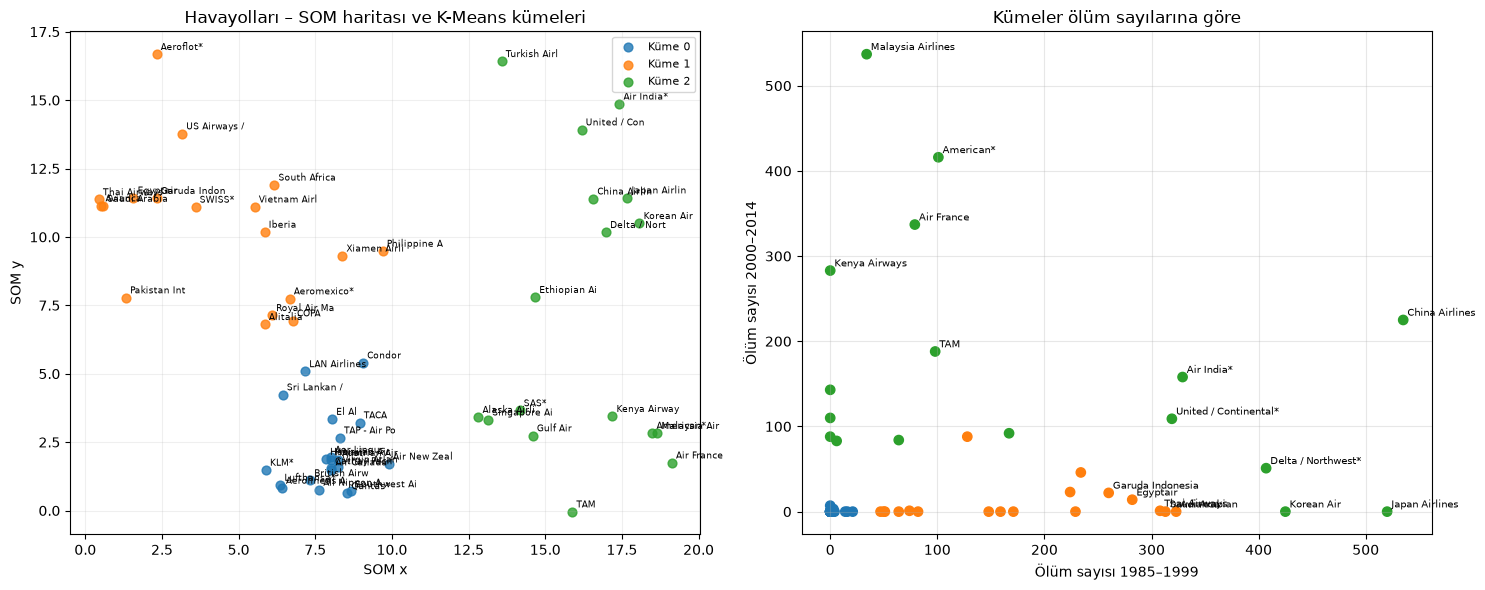

Güvenli      : Aer Lingus, Aerolineas Argentinas, Air Canada, Air New Zealand*, All Nippon Airways, Austrian Airlines, British Airways*, Cathay Pacific*, Condor, El Al, Finnair, Hawaiian Airlines, KLM*, LAN Airlines, Lufthansa*, Qantas*, Southwest Airlines, Sri Lankan / AirLanka, TACA, TAP - Air Portugal, Virgin Atlantic
Orta güvenli : Aeroflot*, Aeromexico*, Alitalia, Avianca, COPA, Egyptair, Garuda Indonesia, Iberia, Pakistan International, Philippine Airlines, Royal Air Maroc, Saudi Arabian, South African, SWISS*, Thai Airways, US Airways / America West*, Vietnam Airlines, Xiamen Airlines
Riskli       : Air France, Air India*, Alaska Airlines*, American*, China Airlines, Delta / Northwest*, Ethiopian Airlines, Gulf Air, Japan Airlines, Kenya Airways, Korean Air, Malaysia Airlines, SAS*, Singapore Airlines, TAM, Turkish Airlines, United / Continental*


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
harita_ciz(hrt, veri["kümeler"].values, "Havayolları – SOM haritası ve K-Means kümeleri", veri["airline"].str[:12], ax=ax[0])
#kümelere göre toplam ölüm sayıları (iki dönem) – kümelerin neye göre ayrıldığını görmek için
renk = [f"C{k}" for k in veri["kümeler"]]
ax[1].scatter(veri["fatalities_85_99"], veri["fatalities_00_14"], c=renk, s=45)
for _, r in veri.iterrows():
    if r["fatalities_85_99"] > 250 or r["fatalities_00_14"] > 150:
        ax[1].annotate(r["airline"], (r["fatalities_85_99"], r["fatalities_00_14"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("Ölüm sayısı 1985–1999"); ax[1].set_ylabel("Ölüm sayısı 2000–2014")
ax[1].set_title("Kümeler ölüm sayılarına göre"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

for s in ["Güvenli", "Orta güvenli", "Riskli"]:
    print(f"{s:13s}:", ", ".join(veri.loc[veri["sınıf"] == s, "airline"]))

In [8]:
#en güvenli kümedeki firmalardan "en iyi" firmayı seçmek: uçuş hacmine göre normalize edilmiş toplam olay sayısı
#(çok uçan bir firmanın daha fazla olay yaşaması doğal; bu yüzden milyar koltuk-km başına bakıyoruz)
guvenli = veri[veri["sınıf"] == "Güvenli"].copy()
guvenli["toplam olay"] = guvenli[girdiler].sum(axis=1)
guvenli["olay / milyar koltuk-km"] = (guvenli["toplam olay"] / (guvenli["avail_seat_km_per_week"] / 1e9)).round(3)
guvenli.sort_values(["olay / milyar koltuk-km", "avail_seat_km_per_week"], ascending=[True, False])[
    ["airline", "avail_seat_km_per_week", "toplam olay", "olay / milyar koltuk-km"]].head(10)

,airline,avail_seat_km_per_week,toplam olay,olay / milyar koltuk-km
48,TAP - Air Portugal,619130754,0,0.000
15,Cathay Pacific*,2582459303,2,0.774
54,Virgin Atlantic,1005248585,1,0.995
23,Finnair,506464950,1,1.974
26,Hawaiian Airlines,493877795,1,2.025
4,Air Canada,1865253802,4,2.144
43,Southwest Airlines,3276525770,9,2.747
37,Qantas*,1917428984,6,3.129
14,British Airways*,3179760952,10,3.145
33,Lufthansa*,3426529504,12,3.502


**Yorum (Uygulama):** SOM + K-Means 56 firmayı **21 güvenli, 18 orta, 17 riskli** olarak ayırdı. Kümelerin ortalamalarına bakınca ayrımın neye göre yapıldığı görülüyor:

- **Güvenli** küme her iki dönemde de neredeyse sıfır ölümle ayrışıyor (ortalama 3 ve 0.5 ölüm).
- **Orta** ve **riskli** kümeler 1985–1999 döneminde birbirine çok benziyor (ortalama 175 ve 181 ölüm). İkisini ayıran şey **2000–2014 dönemi**: orta kümede ölüm sayısı 11'e düşmüş, riskli kümede 171'de kalmış. Yani SOM aslında "eskiden kötüydü ama düzeldi" ile "her iki dönemde de ölümlü kaza yaşadı" ayrımını yapmış. Sağdaki grafikte bu açıkça görülüyor: turuncu noktalar sadece x ekseninde (eski dönem), yeşil noktalar y ekseninde (yeni dönem) yüksek.
- K-Means'in haritada çizdiği sınırlar ölüm sayısı grafiğinde de tutarlı; SOM 6 boyutlu veriyi 2 boyuta indirirken yakınlık ilişkisini korumuş.

"Riskli" kümede Air France, American, Delta, United, Japan Airlines gibi dünyanın en büyük firmaları var. Bu, ham sayıların uçuş hacmini hiç hesaba katmamasından kaynaklanıyor: haftada 3 milyar koltuk-km uçan bir firmanın toplam olay sayısı doğal olarak daha yüksek. Bu yüzden "en iyi firma" sorusunu güvenli küme içinde **milyar koltuk-km başına olay** ile cevapladım: **TAP – Air Portugal** 30 yılda sıfır olayla ilk sırada, ardından Cathay Pacific ve Virgin Atlantic geliyor.

### Ek: Ölçekleme ve uçuş hacmine göre normalize edilmiş SOM
Föydeki kodda girdiler **ham sayılar** olarak veriliyor. SOM, Öklid uzaklığı kullandığı için büyük değerli sütunlar (ölüm sayıları yüzlerce, kaza sayıları birkaç tane) uzaklığı neredeyse tek başına belirliyor. Ayrıca haftada 7 milyar koltuk-km uçan bir firmayla 0.3 milyar uçan bir firma aynı ölçekte karşılaştırılıyor.

Burada aynı ağı, girdileri **milyar koltuk-km başına** oranlara çevirip `StandardScaler` ile standartlaştırarak (her sütun ortalama 0, std 1) tekrar eğitiyorum ve iki sonucu karşılaştırıyorum. Risk puanı, kümedeki 6 standart oranın ortalamasıdır (0 = 56 firmanın ortalaması, negatif = ortalamadan güvenli).

> **Bu bölümde ne yaptım? (basitçe)**
>
> Föydeki kod ham sayıları kullanıyor. Bu iki soruna yol açıyor: (1) ölüm sayıları yüzlerle, kaza sayıları birlerle ifade ediliyor, uzaklığı sadece ölüm sayısı belirliyor; (2) çok uçan şirketin çok kazası olması doğal, haftada 3 milyar koltuk-km uçan Lufthansa ile 0.3 milyar uçan Aer Lingus aynı kefeye konuyor.
>
> Sayıları uçuş hacmine böldüm (milyar koltuk-km başına kaza) ve her sütunu aynı ölçeğe getirdim. Aynı ağı tekrar eğittim ve iki sonucu karşılaştırdım. Sıralama ciddi şekilde değişti.

In [9]:
#her sayıyı haftalık milyar koltuk-km'ye böl → uçuş hacminden bağımsız oran
oran = X.div(veri["avail_seat_km_per_week"] / 1e9, axis=0)
#her sütun ortalama 0, std 1 → 6 girdinin uzaklığa katkısı eşitlenir
Xo = StandardScaler().fit_transform(oran)
net_o, hrt_o = som_egit(Xo)
km_o = KMeans(n_clusters=3, max_iter=300, random_state=0).fit(hrt_o)
veri["küme (oran)"] = km_o.labels_

ozet_o = veri.groupby("küme (oran)")[girdiler].mean().round(2)
#risk puanı: kümedeki standart oranların ortalaması
ozet_o["risk puanı"] = pd.DataFrame(Xo).groupby(veri["küme (oran)"]).mean().mean(axis=1).round(2)
ozet_o["firma sayısı"] = veri["küme (oran)"].value_counts().sort_index()
isim_o = dict(zip(ozet_o["risk puanı"].sort_values().index, ["Güvenli", "Orta güvenli", "Riskli"]))
ozet_o["sınıf"] = ozet_o.index.map(isim_o)
veri["sınıf (oran)"] = veri["küme (oran)"].map(isim_o)
print(ozet_o.sort_values("risk puanı"), "\n")

#iki yaklaşımın sınıflarını çapraz tabloyla karşılaştır
print(pd.crosstab(veri["sınıf"], veri["sınıf (oran)"], rownames=["Ham sayılar"], colnames=["Oranlar"]))

20x20 SOM, 10000 epok eğitildi (67 sn). Harita koordinatları: (56, 2)
             incidents_85_99  fatal_accidents_85_99  fatalities_85_99  incidents_00_14  fatal_accidents_00_14  fatalities_00_14  risk puanı  firma sayısı  \
küme (oran)                                                                                                                                                 
1                       3.80                   0.67             28.20             4.47                   0.27             11.93       -0.30            15   
0                       5.93                   2.21            121.57             3.68                   0.68             76.46       -0.24            28   
2                      13.77                   3.85            189.85             4.69                   1.08             60.69        0.88            13   

                    sınıf  
küme (oran)                
1                 Güvenli  
0            Orta güvenli  
2                  Riskli   

Or

In [10]:
for s in ["Güvenli", "Orta güvenli", "Riskli"]:
    print(f"{s:13s}:", ", ".join(veri.loc[veri["sınıf (oran)"] == s, "airline"]))

Güvenli      : Aerolineas Argentinas, Aeromexico*, Air New Zealand*, Alaska Airlines*, Alitalia, All Nippon Airways, Austrian Airlines, British Airways*, Hawaiian Airlines, Iberia, Qantas*, Southwest Airlines, Sri Lankan / AirLanka, Turkish Airlines, Xiamen Airlines
Orta güvenli : Aer Lingus, Air Canada, Air France, Air India*, American*, Cathay Pacific*, Condor, COPA, Delta / Northwest*, El Al, Finnair, Gulf Air, Japan Airlines, Kenya Airways, KLM*, Korean Air, LAN Airlines, Lufthansa*, Malaysia Airlines, Singapore Airlines, South African, SWISS*, TAP - Air Portugal, Thai Airways, United / Continental*, US Airways / America West*, Vietnam Airlines, Virgin Atlantic
Riskli       : Aeroflot*, Avianca, China Airlines, Egyptair, Ethiopian Airlines, Garuda Indonesia, Pakistan International, Philippine Airlines, Royal Air Maroc, SAS*, Saudi Arabian, TACA, TAM


**Yorum (Ek):** Oranlar ve standartlaştırmayla sonuç ciddi şekilde değişti: **15 güvenli, 28 orta, 13 riskli**. Çapraz tabloda ham sayılarla "riskli" denen 17 firmadan sadece 4'ü oranlarla da riskli kaldı; Air France, American, United, Singapore Airlines "orta"ya geçti. Buna karşılık ham sayılarla güvenli görünen 21 firmanın 11'i oranlarla ortaya düştü; bunlar az uçan, az kazası olan ama **uçuş başına** kazası düşük olmayan firmalar (Aer Lingus, KLM, Lufthansa gibi).

Oranlarla "riskli" çıkan 13 firma (Aeroflot, Avianca, China Airlines, Ethiopian, Garuda, Pakistan International, Philippine Airlines, TACA…) havacılık güvenliği literatüründe de genelde sorunlu sayılan firmalar; ham sayılar büyük firmaların kalabalığında bunları gizliyordu. Risk puanı burada standartlaştırılmış oranların ortalaması: riskli küme +0.88 (ortalamanın bir standart sapma üstünde), güvenli küme −0.30.

İki önemli not:
1. Hangi ön işlemenin "doğru" olduğu veriye değil **soruya** bağlı. "Hangi firmada toplamda daha çok insan öldü?" sorusuna ham sayılar, "bu firmayla uçmak ne kadar riskli?" sorusuna oranlar cevap verir. Föydeki problem tanımı ("en iyi hava yolu") ikinci soruya yakın.
2. 56 örnekle 3 küme küçük bir problem; ön işleme ve rastgele başlangıç (tohum) değişince küme üyelikleri de değişiyor. Bu, kümelemenin "doğru cevap" değil, veriye bakmanın bir yolu olduğunu gösteriyor.

## Soru 1 – AVM müşterilerinin SOM ile kümelenmesi
**Problem:** AVM müşterilerini alışveriş davranışlarına göre segmentlere ayırmak (pazarlama hangi gruba ne sunmalı?).
**Girdiler:** Yaş, yıllık gelir (bin $), harcama puanı (1–100, AVM'nin müşteriye verdiği puan).
**Çıktı:** Müşteri segmentleri. Havayolu örneğinden farklı olarak burada küme sayısı önceden bilinmiyor; **dirsek yöntemi ve siluet skoruna** bakarak seçiyorum.

Ön işleme: `CustomerID` bir sıra numarası olduğu için çıkarıldı. Yaş (18–70), gelir (15–137) ve puan (1–99) farklı aralıklarda olduğundan `StandardScaler` ile ortalama 0, standart sapma 1 yapıldı. Cinsiyet girdiye alınmadı, kümeler oluştuktan sonra profil için kullanıldı.

> **Bu soruda ne yaptım? (basitçe)**
>
> 200 AVM müşterisinin yaşı, yıllık geliri ve AVM'nin verdiği harcama puanı var. Bunları gruplara ayırmak istiyoruz: pazarlama hangi gruba ne kampanya yapsın?
>
> Üç özellik farklı aralıklarda olduğu için önce hepsini aynı ölçeğe getirdim (standartlaştırma). Sonra havayolundaki gibi SOM eğittim ve haritadaki konumlara K-Means uyguladım.
>
> Burada küme sayısı föydeki gibi önceden belli değildi. 2'den 8'e kadar denedim, dirsek ve siluet grafiklerine baktım, 6 küme seçtim. Her kümenin ortalama yaş/gelir/puanına bakınca "genç ve çok harcayan", "zengin ama az harcayan" gibi anlamlı segmentler çıktı.

In [11]:
mall = pd.read_csv("Mall_Customers.csv")
print(mall.shape)
print(mall.isna().sum().sum(), "eksik değer")
mall.head()

(200, 5)
0 eksik değer


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [12]:
mall_ozellik = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
sc_mall = StandardScaler().fit(mall[mall_ozellik])
Xm = sc_mall.transform(mall[mall_ozellik])          # 200 × 3, standartlaştırılmış

#ağın oluşturulması, eğitilmesi ve müşterilerin haritaya yerleştirilmesi (uygulamadaki ayarlarla)
net_m, hrt_m = som_egit(Xm)

20x20 SOM, 10000 epok eğitildi (63 sn). Harita koordinatları: (200, 2)


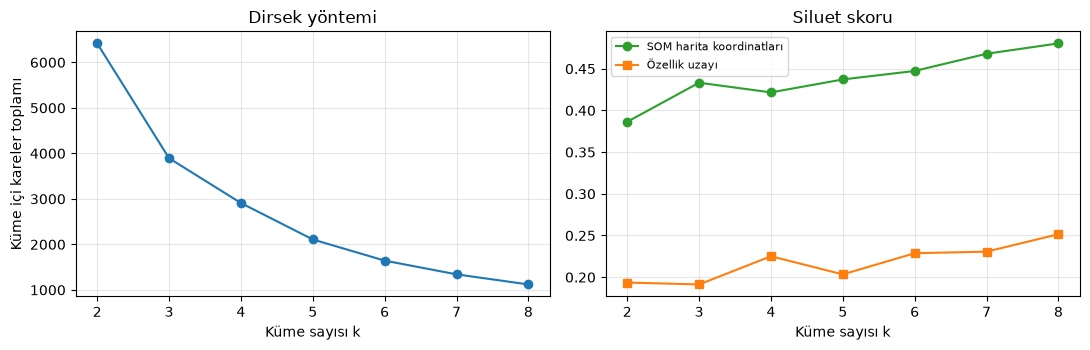

   siluet (harita)  siluet (özellik)
k                                   
2            0.386             0.194
3            0.433             0.191
4            0.422             0.225
5            0.437             0.203
6            0.447             0.229
7            0.468             0.231
8            0.480             0.252


In [13]:
#küme sayısının seçimi: k = 2..8 için K-Means + siluet skoru (1'e yakın = kümeler iyi ayrılmış)
#K-Means harita koordinatlarına uygulandığı için siluet iki yerde ölçülüyor: haritada ve asıl özellik uzayında
ks = range(2, 9)
sil_m, sil_m2, ine_m = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, max_iter=300, random_state=0, n_init=10).fit(hrt_m)
    sil_m.append(silhouette_score(hrt_m, km.labels_))          # harita koordinatlarında
    sil_m2.append(silhouette_score(Xm, km.labels_))         # asıl (standartlaştırılmış) özellik uzayında
    ine_m.append(km.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ks, ine_m, "o-"); ax[0].set_title("Dirsek yöntemi"); ax[0].set_xlabel("Küme sayısı k"); ax[0].set_ylabel("Küme içi kareler toplamı")
ax[1].plot(ks, sil_m, "o-", color="C2", label="SOM harita koordinatları"); ax[1].plot(ks, sil_m2, "s-", color="C1", label="Özellik uzayı")
ax[1].set_title("Siluet skoru"); ax[1].legend(fontsize=8); ax[1].set_xlabel("Küme sayısı k")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"siluet (harita)": np.round(sil_m, 3), "siluet (özellik)": np.round(sil_m2, 3)}, index=pd.Index(ks, name="k")))

In [14]:
#siluet k ile yavaşça artıyor, belirgin bir tepe yok (bkz. yorum); k = 6'da özellik uzayı skoru düzleşiyor ve
#segmentler hâlâ yorumlanabilir büyüklükte (her biri 25+ müşteri). Daha fazla küme, aynı segmenti bölüyor.
K_MALL = 6
print("Seçilen küme sayısı:", K_MALL)
kmeans_m = KMeans(n_clusters=K_MALL, max_iter=300, random_state=0, n_init=10)
mall["kümeler"] = kmeans_m.fit_predict(hrt_m)
mall["kümeler"].values

Seçilen küme sayısı: 6


array([3, 4, 3, 4, 3, 4, 3, 4, 2, 4, 2, 4, 2, 4, 3, 4, 3, 4, 2, 4, 3, 4,
       2, 0, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 3, 0, 3, 4, 2, 4, 3, 0,
       3, 4, 0, 3, 3, 3, 0, 0, 0, 0, 4, 3, 0, 2, 3, 0, 2, 3, 2, 0, 2, 4,
       2, 2, 4, 3, 2, 2, 0, 0, 0, 3, 2, 4, 3, 2, 0, 0, 2, 2, 3, 2, 0, 3,
       4, 2, 2, 3, 2, 3, 3, 3, 2, 3, 2, 3, 3, 2, 2, 3, 0, 3, 2, 0, 2, 2,
       2, 3, 5, 3, 3, 3, 2, 0, 0, 0, 1, 5, 0, 0, 3, 1, 5, 0, 2, 0, 5, 0,
       3, 1, 5, 1, 5, 1, 5, 0, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 0, 5, 0,
       5, 1, 5, 1, 5, 1, 2, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1,
       5, 1, 5, 1, 5, 1, 5, 1, 1, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1,
       5, 1], dtype=int32)

In [15]:
#kümelerin profili: her kümenin ortalama yaş, gelir, harcama puanı ve kadın oranı
prof_m = mall.groupby("kümeler")[mall_ozellik].mean().round(1)
prof_m["müşteri sayısı"] = mall["kümeler"].value_counts().sort_index()
prof_m["kadın oranı"] = mall.groupby("kümeler")["Genre"].apply(lambda g: (g == "Female").mean()).round(2)
prof_m

,Age,Annual Income (k$),Spending Score (1-100),müşteri sayısı,kadın oranı
kümeler,,,,,
0,45.4,55.6,61.7,30,0.53
1,31.6,89.1,80.2,34,0.59
2,57.1,47.8,37.3,39,0.54
3,28.2,47.2,40.5,37,0.68
4,26.2,30.3,74.8,25,0.56
5,40.2,87.0,18.3,35,0.46


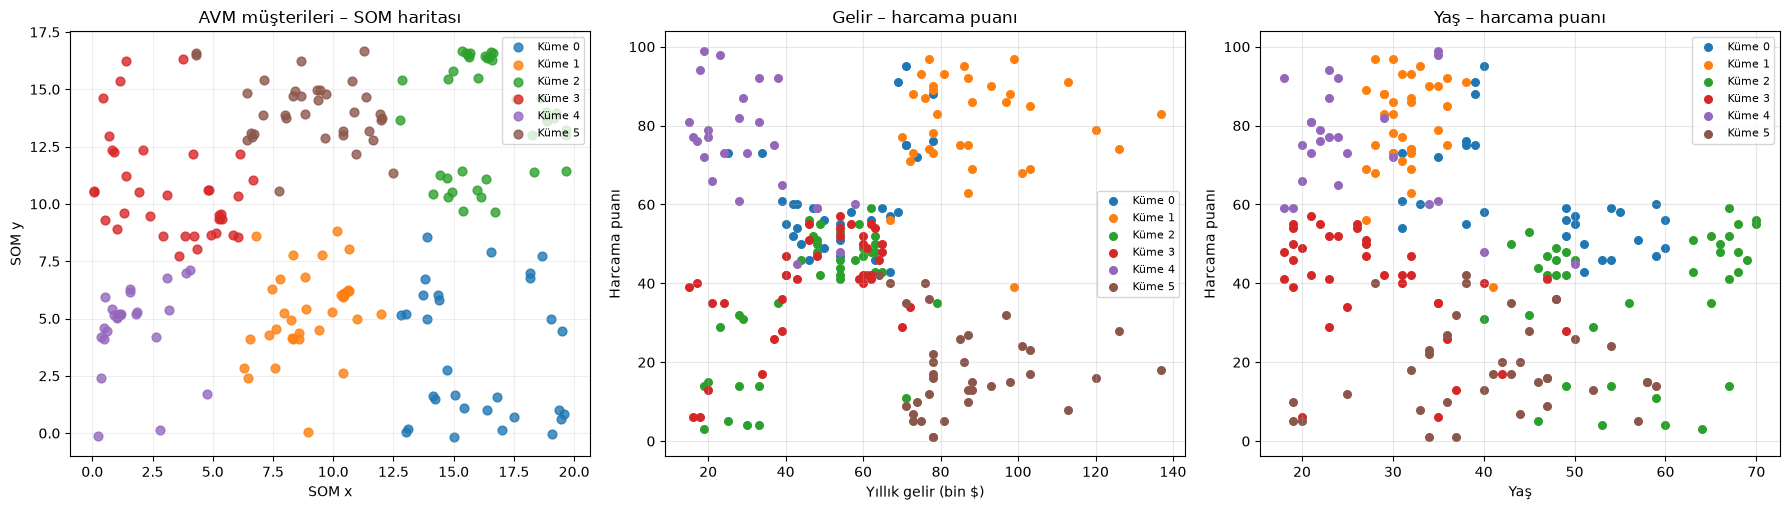

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
harita_ciz(hrt_m, mall["kümeler"].values, "AVM müşterileri – SOM haritası", ax=ax[0])
for k in range(K_MALL):
    m = mall["kümeler"] == k
    ax[1].scatter(mall.loc[m, "Annual Income (k$)"], mall.loc[m, "Spending Score (1-100)"], s=30, color=f"C{k}", label=f"Küme {k}")
    ax[2].scatter(mall.loc[m, "Age"], mall.loc[m, "Spending Score (1-100)"], s=30, color=f"C{k}", label=f"Küme {k}")
ax[1].set_xlabel("Yıllık gelir (bin $)"); ax[1].set_ylabel("Harcama puanı"); ax[1].set_title("Gelir – harcama puanı")
ax[2].set_xlabel("Yaş"); ax[2].set_ylabel("Harcama puanı"); ax[2].set_title("Yaş – harcama puanı")
for a in ax[1:]: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

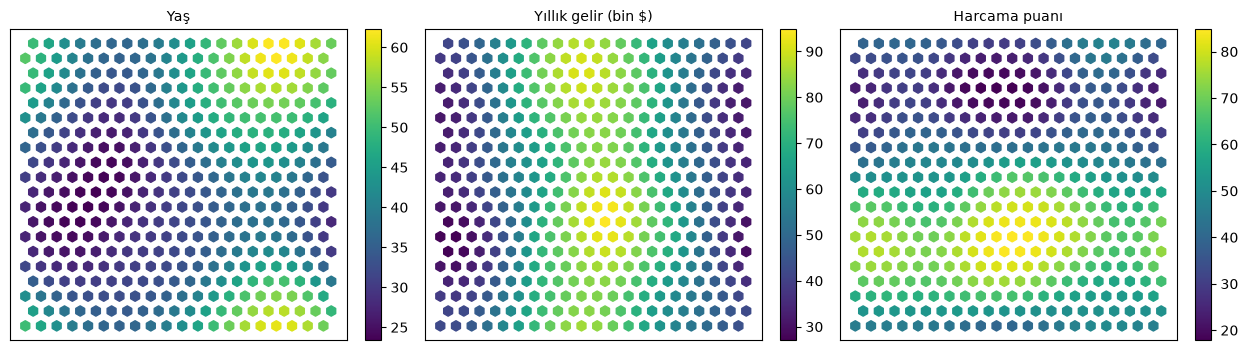

In [17]:
#bileşen düzlemleri: her düğümün ağırlığı (gerçek birimlerde). Aynı bölgede benzer renk = SOM o özelliği haritaya yaymış
bilesen_duzlemi(net_m, ["Yaş", "Yıllık gelir (bin $)", "Harcama puanı"], scaler=sc_mall)

**Yorum (Soru 1):** Harita koordinatlarındaki siluet skoru k arttıkça artmaya devam ediyor (0.39 → 0.48); çünkü K-Means 2 boyutlu haritayı istediği kadar parçaya kolayca bölebiliyor. Asıl özellik uzayındaki siluet ise 4 kümeden sonra 0.20–0.25 bandında düzleşiyor. Skor tek başına 8'i işaret etse de 8 kümede segmentler 15–20 kişiye düşüyor ve aynı gelir–puan bölgesini yaşa göre tekrar tekrar bölüyor. **6 küme** hem skorun düzleştiği yerde hem de her segmentin iş anlamı olan bir seçim:

| Küme | Kişi | Profil | Pazarlama için anlamı |
|---|---|---|---|
| 1 | 34 | 32 yaş, gelir 89k, puan 80 | **Hedef müşteri**: zengin ve çok harcıyor |
| 5 | 35 | 40 yaş, gelir 87k, puan 18 | **Kazanılabilir potansiyel**: parası var ama bu AVM'de harcamıyor |
| 4 | 25 | 26 yaş, gelir 30k, puan 75 | Genç, düşük gelirli ama çok harcıyor (kampanya/indirim duyarlı) |
| 3 | 37 | 28 yaş, gelir 47k, puan 40 | Genç, orta gelir, orta-az harcama (kadın oranı %68) |
| 0 | 30 | 45 yaş, gelir 56k, puan 62 | Orta yaş, orta gelir, ortanın üstü harcama |
| 2 | 39 | 57 yaş, gelir 48k, puan 37 | Yaşlı, orta gelir, az harcama |

Bu veri seti klasik K-Means ile gelir–puan düzleminde 5 kümeye (dört köşe + orta) ayrılır. SOM üç özelliği birlikte kullandığı için ortadaki büyük grubu **yaşa göre** üçe böldü (3: genç, 0: orta yaş, 2: yaşlı). Gelir–puan grafiğinde bu üç küme üst üste biniyor; yaş–puan grafiğinde ayrışıyor. Bileşen düzlemleri de bunu doğruluyor: harcama puanı haritanın alt yarısında, gelir ortasında, yaş sağ kenarlarda yüksek; kümeler bu bölgelerin kesişimleri.

## Soru 2 – Kredi kartı kullanıcılarının SOM ile kümelenmesi
**Problem:** Kredi kartı sahiplerini kullanım davranışlarına göre segmentlere ayırmak (pazarlama stratejisi).
**Girdiler:** 17 davranış özelliği: bakiye, alışveriş tutarları (tek çekim / taksitli), nakit avans, alışveriş sıklıkları, kredi limiti, ödemeler, asgari ödeme, tam ödeme oranı, kart süresi.
**Çıktı:** Müşteri segmentleri; küme sayısı yine siluet skoruyla seçiliyor.

Ön işleme:
- `CUST_ID` kimlik numarası olduğu için çıkarıldı.
- `MINIMUM_PAYMENTS` (313) ve `CREDIT_LIMIT` (1) eksik değerleri **medyanla** dolduruldu.
- Tutar sütunları çok çarpık (çoğu müşteri az harcıyor, birkaç müşteri çok fazla). `log1p` ile sıkıştırıldı, sonra tüm sütunlar `StandardScaler` ile standartlaştırıldı. Bunu yapmazsak bakiye ve limit gibi binlerle ifade edilen sütunlar, 0–1 arasındaki sıklık sütunlarını Öklid uzaklığında tamamen bastırır.

> **Bu soruda ne yaptım? (basitçe)**
>
> 8950 kredi kartı müşterisinin 17 davranış bilgisi var: ne kadar bakiye taşıyor, ne kadar alışveriş yapıyor, nakit avans çekiyor mu, borcunu tam ödüyor mu…
>
> Önce temizlik: 313 kişide asgari ödeme bilgisi boştu, medyanla doldurdum. Tutar sütunları çok çarpık (çoğu kişi az, birkaç kişi çok fazla harcıyor), log aldım ve hepsini aynı ölçeğe getirdim.
>
> SOM'u 8950 müşteriyle eğitip haritaya yerleştirdim (bu adım yaklaşık 8 dakika sürdü, çünkü kütüphane her örneğin 400 nöronla uzaklığını tek tek hesaplıyor). Siluet skoru en yüksek 3 kümede çıktı: alışveriş yapanlar, nakit avans çekenler ve kartı neredeyse hiç kullanmayanlar.

In [18]:
cc = pd.read_csv("CC_GENERAL.csv")
print(cc.shape)
print(cc.isna().sum()[cc.isna().sum() > 0])
cc.describe().T.round(2)

(8950, 18)
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


In [19]:
cc_X = cc.drop(["CUST_ID"], axis=1)
cc_X = cc_X.fillna(cc_X.median())                  # eksikleri medyanla doldur
#0-1 arasındaki sıklık/oran sütunları ve TENURE hariç tüm tutar sütunlarına log1p
tutar = [c for c in cc_X.columns if "FREQUENCY" not in c and c not in ["PRC_FULL_PAYMENT", "TENURE"]]
cc_log = cc_X.copy(); cc_log[tutar] = np.log1p(cc_log[tutar])
Xc = StandardScaler().fit_transform(cc_log)        # 8950 × 17
print("log1p uygulanan sütunlar:", tutar)

#ağın oluşturulması, eğitilmesi ve 8950 müşterinin haritaya yerleştirilmesi
net_c, hrt_c = som_egit(Xc)

log1p uygulanan sütunlar: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']


20x20 SOM, 10000 epok eğitildi (96 sn). Harita koordinatları: (8950, 2)


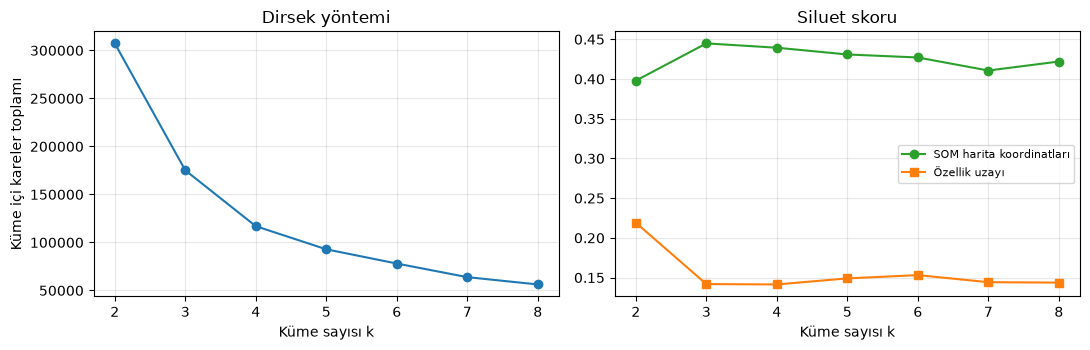

   siluet (harita)  siluet (özellik)
k                                   
2            0.398             0.219
3            0.445             0.142
4            0.439             0.141
5            0.431             0.149
6            0.427             0.153
7            0.411             0.144
8            0.422             0.144


In [20]:
#küme sayısının seçimi (siluet 8950 nokta için hızlı olsun diye 3000'lik örneklemle hesaplanıyor)
sil_c, sil_c2, ine_c = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, max_iter=300, random_state=0, n_init=10).fit(hrt_c)
    sil_c.append(silhouette_score(hrt_c, km.labels_, sample_size=3000, random_state=0))          # harita koordinatlarında
    sil_c2.append(silhouette_score(Xc, km.labels_, sample_size=3000, random_state=0))         # asıl (standartlaştırılmış) özellik uzayında
    ine_c.append(km.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ks, ine_c, "o-"); ax[0].set_title("Dirsek yöntemi"); ax[0].set_xlabel("Küme sayısı k"); ax[0].set_ylabel("Küme içi kareler toplamı")
ax[1].plot(ks, sil_c, "o-", color="C2", label="SOM harita koordinatları"); ax[1].plot(ks, sil_c2, "s-", color="C1", label="Özellik uzayı")
ax[1].set_title("Siluet skoru"); ax[1].legend(fontsize=8); ax[1].set_xlabel("Küme sayısı k")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"siluet (harita)": np.round(sil_c, 3), "siluet (özellik)": np.round(sil_c2, 3)}, index=pd.Index(ks, name="k")))

In [21]:
#harita koordinatlarındaki siluet k = 3'te en yüksek; özellik uzayındaki skorla birlikte değerlendirme yorumda
K_CC = 3
print("Seçilen küme sayısı:", K_CC)
kmeans_c = KMeans(n_clusters=K_CC, max_iter=300, random_state=0, n_init=10)
cc["kümeler"] = kmeans_c.fit_predict(hrt_c)
print(cc["kümeler"].value_counts().sort_index())

Seçilen küme sayısı: 3
kümeler
0    3685
1    2520
2    2745
Name: count, dtype: int64


In [22]:
#kümelerin profili (gerçek birimlerde, medyan: çarpık dağılımda ortalamadan daha temsilci)
prof_sutun = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
              "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
prof_c = cc.groupby("kümeler")[prof_sutun].median().round(2)
prof_c.insert(0, "müşteri sayısı", cc["kümeler"].value_counts().sort_index())
prof_c.T

kümeler,0,1,2
müşteri sayısı,3685.00,2520.00,2745.00
BALANCE,303.05,918.37,1758.98
PURCHASES,853.44,0.00,378.58
ONEOFF_PURCHASES,134.90,0.00,270.00
INSTALLMENTS_PURCHASES,450.00,0.00,0.00
CASH_ADVANCE,0.00,560.21,1008.78
PURCHASES_FREQUENCY,0.92,0.00,0.25
CASH_ADVANCE_FREQUENCY,0.00,0.17,0.25
CREDIT_LIMIT,4000.00,2500.00,4500.00
PAYMENTS,955.23,498.36,1259.72


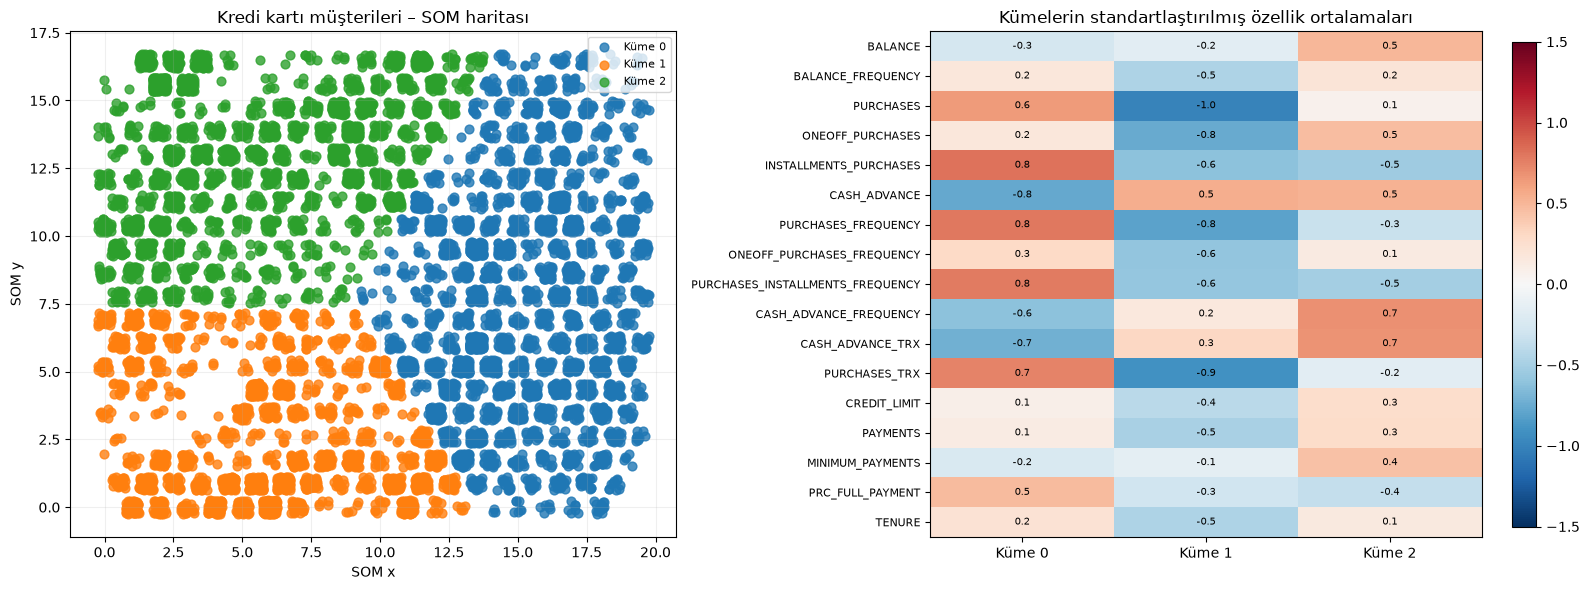

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
harita_ciz(hrt_c, cc["kümeler"].values, "Kredi kartı müşterileri – SOM haritası", ax=ax[0])
#kümelerin özellik "parmak izi": her özelliğin küme ortalaması (standartlaştırılmış, 0 = genel ortalama)
z = pd.DataFrame(Xc, columns=cc_X.columns).groupby(cc["kümeler"]).mean()
im = ax[1].imshow(z.T, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax[1].set_yticks(range(z.shape[1])); ax[1].set_yticklabels(z.columns, fontsize=8)
ax[1].set_xticks(range(K_CC)); ax[1].set_xticklabels([f"Küme {k}" for k in range(K_CC)])
for i in range(z.shape[1]):
    for k in range(K_CC):
        ax[1].text(k, i, f"{z.iloc[k, i]:.1f}", ha="center", va="center", fontsize=7)
ax[1].set_title("Kümelerin standartlaştırılmış özellik ortalamaları"); plt.colorbar(im, ax=ax[1], fraction=0.04)
plt.tight_layout(); plt.show()

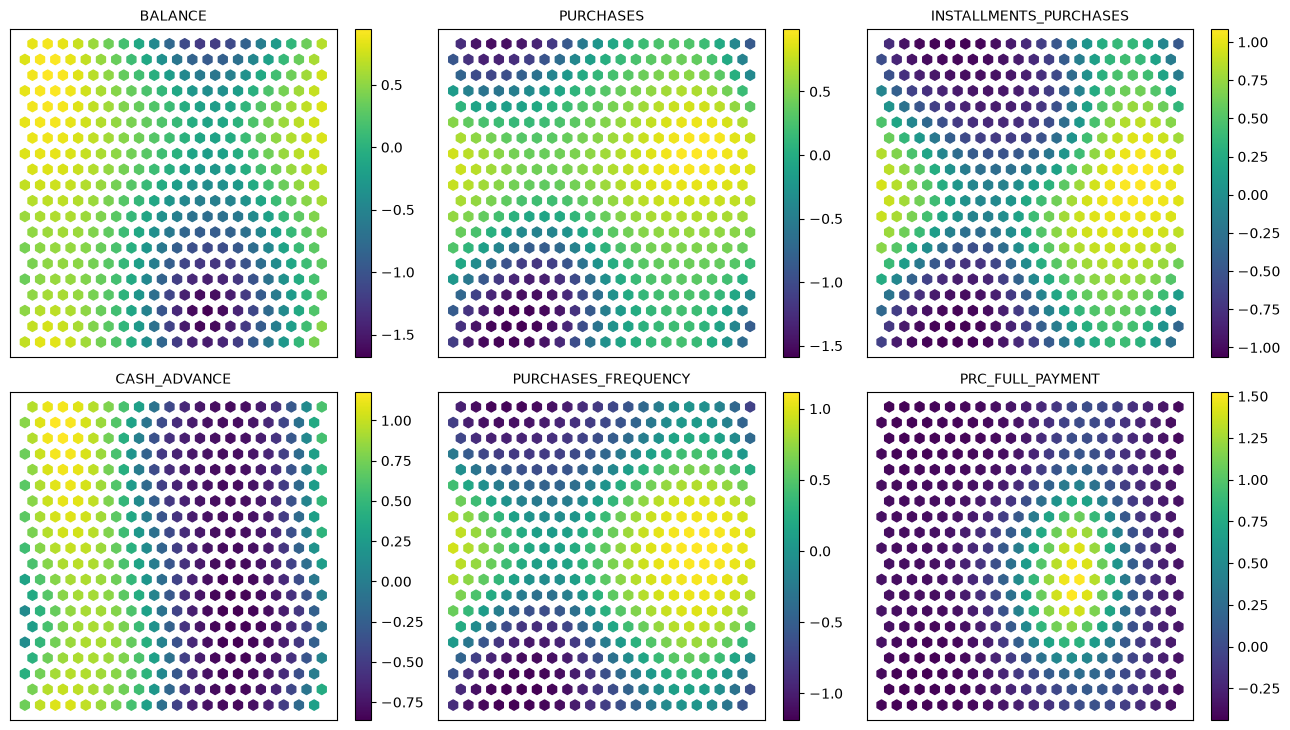

In [24]:
#SOM bileşen düzlemleri: davranışın harita üzerindeki dağılımı (standartlaştırılmış log ölçekte)
W = np.array([n.weights for n in net_c.nodeList], dtype=float)
P = np.array([n.pos for n in net_c.nodeList])
goster = ["BALANCE", "PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
fig, axs = plt.subplots(2, 3, figsize=(13, 7.4))
for ax, ad in zip(axs.ravel(), goster):
    i = list(cc_X.columns).index(ad)
    s = ax.scatter(P[:, 0], P[:, 1], c=W[:, i], cmap="viridis", s=55, marker="h")
    ax.set_title(ad, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(s, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

**Yorum (Soru 2):** Harita koordinatlarında siluet en yüksek değerini **k = 3**'te alıyor (0.445). Özellik uzayındaki siluet düşük (0.14): 17 boyutlu davranış verisinde müşteriler keskin gruplar hâlinde değil, bir **süreklilik** içinde dağılıyor; SOM haritası bu sürekliliği 2 boyuta açıyor, K-Means de üzerine sınır çiziyor. Üç segment, ısı haritasındaki parmak izleriyle net ayrışıyor:

| Küme | Kişi | Davranış | Banka için anlamı |
|---|---|---|---|
| 0 | 3685 (%41) | Alışveriş sıklığı 0.92, taksitli alışveriş yüksek, nakit avans 0, bakiye düşük (303), tam ödeme oranı en yüksek | **Ödeme aracı kullanıcıları**: kartı harcayıp borcunu kapatıyor; faiz geliri az, risk düşük, komisyon geliri yüksek |
| 2 | 2745 (%31) | Bakiye en yüksek (1759), nakit avans 1009, nakit avans sıklığı 0.25, tam ödeme 0, asgari ödeme yüksek | **Borç taşıyanlar**: kartı kredi gibi kullanıyor; faiz geliri yüksek ama temerrüt riski de yüksek |
| 1 | 2520 (%28) | Alışveriş 0, sıklık 0, limit düşük (2500), ödeme düşük, kart süresi kısa | **Pasif kullanıcılar**: kartı neredeyse hiç kullanmıyor, kullanınca nakit çekiyor; aktivasyon kampanyası hedefi |

Bileşen düzlemlerinde nakit avans haritanın **sol** yarısında, alışveriş ve alışveriş sıklığı **sağ** yarısında yüksek; tam ödeme oranı sadece sağ-alt köşede yükseliyor. SOM, "alışveriş yapan" ile "nakit çeken" davranışlarını haritanın iki yarısına ayırmış, K-Means de bu sınırı izlemiş. Sol yarının üst/alt bölünmesi bakiye ile oluyor: üstte yüksek bakiye taşıyanlar (küme 2), altta düşük bakiyeli pasifler (küme 1).

Pratik not: SimpSOM saf Python döngüsüyle çalıştığı için 8950 müşterinin haritaya yerleştirilmesi 8 dakika sürdü (56 havayolu için 1 dakika). Eğitim süresi örnek sayısından bağımsız (her epokta tek örnek), ama `project` her örnek için 400 nöronla uzaklık hesaplıyor. Daha büyük veride MiniSom gibi NumPy tabanlı bir kütüphane ya da örneklem gerekir.

## Genel değerlendirme
- **SOM ne yapıyor?** Denetimsiz bir sinir ağı: etiket olmadan, benzer örnekleri haritada yan yana koymayı öğreniyor. Uygulamada görevi boyut indirgeme (6, 3 ve 17 boyut → 2 boyut); son sınırları K-Means çiziyor. Harita koordinatlarına K-Means uygulamak, asıl veriye uygulamaktan farklı sonuç verebilir (Soru 1'de ortadaki grubun yaşa göre bölünmesi gibi), çünkü SOM yakınlıkları kendi ölçütüne göre yeniden düzenliyor.
- **Ölçekleme şart.** SOM ve K-Means Öklid uzaklığı kullanıyor. Föydeki ham havayolu verisinde ölüm sayıları (yüzler) kaza sayılarını (birler) bastırıyor; kredi kartı verisinde bakiye (binler) sıklıkları (0–1) bastırırdı. Ek bölümde aynı ağın ölçekleme ile bambaşka bir "riskli" listesi vermesi bunun kanıtı.
- **Küme numarası anlamsız, profil anlamlı.** 0/1/2 etiketleri rastgele; her kümenin ortalamasına/medyanına bakıp isim vermek gerekiyor. Föydeki "en iyi firmalar 1 numaralı kümede" sonucu bu yüzden sayısal bir ölçüte bağlanmalı.
- **Küme sayısı.** Föyde 3 küme problem tanımından geliyor. Soru 1 ve 2'de bunu dirsek + siluet + yorumlanabilirlik ile seçtim; siluet tek başına yeterli değil (harita koordinatlarında k ile monoton artabiliyor).
- **Sonuç = soru.** "Toplamda kaç kişi öldü" ile "uçuş başına risk" farklı kümeler veriyor. Kümeleme bir keşif aracı; hangisinin doğru olduğuna veri değil, problem tanımı karar veriyor.